# 02 — Preprocessing & Baseline Models
**Project:** Detecting ChatGPT-Generated Text: A Comparison of Classical Machine Learning, Perplexity-Based and Fine-Tuned Transformer Detectors

Initial implementation for the midterm:
1. **Clean** the data and **normalise formatting** (remove the artifacts found in notebook 01).
2. Build a **balanced paired dataset** and split it by question (train / validation / test).
3. Train and compare the first detectors:
   - **Length-only** model (sanity check)
   - **TF-IDF + Logistic Regression** — on raw vs. cleaned text
   - **Neural bag-of-embeddings classifier in PyTorch**
   - **GPT-2 perplexity** (zero-shot, no training)
4. **Cross-domain test**: train on 4 domains, test on the unseen 5th.

In [1]:
import os, warnings
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'      # no download progress bars in the output
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'         # only real errors from transformers
warnings.filterwarnings('ignore')
import re, json, time, random
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import torch, torch.nn as nn

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
FIG = Path('../reports/figures'); DATA = Path('../data')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_parquet(DATA / 'interim' / 'hc3_long.parquet')
print(df.shape)

(85449, 7)


## 1. Cleaning and formatting normalisation
The **same** rules are applied to human and ChatGPT texts, so we do not change *who* wrote the text — only how it was stored.

In [2]:
RULES = [
    (r'\\n', ' '),                                          # literal "\n" characters left from scraping
    (r'\s+', ' '),                                        # line breaks / repeated spaces -> one space
    (r'([a-z0-9\)])\.([A-Z])', r'\1. \2'),                  # "end.Next"   -> "end. Next"
    (r'\s+([,.!?;:%])', r'\1'),                             # "word , x"   -> "word, x"
    (r"\s+(n't|'s|'re|'ve|'ll|'d|'m)\b", r'\1'),            # "do n't"     -> "don't"
    (r'\(\s+', '('), (r'\s+\)', ')'),                       # "( x )"      -> "(x)"
    (r'(\w)\s+-\s+(\w)', r'\1-\2'),                         # "well - known" -> "well-known"
    (r'"\s+([^"]*?)\s+"', r'"\1"'),                         # '" quote "'  -> '"quote"'
    (r'\$\s+(\d)', r'$\1'),                                 # "$ 5"        -> "$5"
]

def normalise(text: str) -> str:
    for pat, rep in RULES:
        text = re.sub(pat, rep, text)
    return text.strip()

examples = df[df.label == 'human'].text.iloc[[1, 5]].tolist() + df[df.label == 'chatgpt'].text.iloc[[0]].tolist()
for t in examples:
    print('BEFORE:', t[:160].replace('\n', '\\n')); print('AFTER: ', normalise(t)[:160]); print()

BEFORE: I know this question has a lot of answers already, but I feel the answers are phrased either strongly against, or mildly for, co-signing. What it amounts down t
AFTER:  I know this question has a lot of answers already, but I feel the answers are phrased either strongly against, or mildly for, co-signing. What it amounts down t

BEFORE: The main disadvantage is that interest rates are higher for the interest-only loan. It's higher risk to the bank, since the principal outstanding is higher for 
AFTER:  The main disadvantage is that interest rates are higher for the interest-only loan. It's higher risk to the bank, since the principal outstanding is higher for 

BEFORE: Historical price-to-earnings (P/E) ratios for small-cap and large-cap stocks can vary significantly over time and may not be directly comparable due to the diff
AFTER:  Historical price-to-earnings (P/E) ratios for small-cap and large-cap stocks can vary significantly over time and may not be directly comparable 

### Cleaning protocol
Every step and the number of answers it removes are logged (Table: cleaning protocol).

In [3]:
steps = [('Original HC3 (English)', len(df))]
df = df[df.text.str.strip() != '']; steps.append(('1. Remove empty answers', len(df)))
df = df[~df.is_error].copy();     steps.append(('2. Remove ChatGPT server error messages', len(df)))
df['text_clean'] = df.text.map(normalise)
df['n_words'] = df.text_clean.str.split().str.len()
steps.append(('3. Normalise formatting (no rows removed)', len(df)))
df = df[df.n_words >= 5];          steps.append(('4. Remove answers shorter than 5 words', len(df)))
df = df.drop_duplicates('text_clean'); steps.append(('5. Remove exact duplicates (after normalisation)', len(df)))
protocol = pd.DataFrame(steps, columns=['step', 'answers left'])
protocol['removed'] = (-protocol['answers left'].diff()).fillna(0).astype(int)
protocol

,step,answers left,removed
0,Original HC3 (English),85449,0
1,1. Remove empty answers,85431,18
2,2. Remove ChatGPT server error messages,85331,100
3,3. Normalise formatting (no rows removed),85331,0
4,4. Remove answers shorter than 5 words,85316,15
5,5. Remove exact duplicates (after normalisation),79304,6012


### Did the artifacts disappear?

In [4]:
patterns = {
    'space before punctuation': r' [,.!?;:]',
    "split contractions (do n't)": r" n't\b",
    'missing space after period': r'[a-z]\.[A-Z]',
    'line break': r'\n',
    'literal "\\n" characters': r'\\n',
}
def share(col):
    return pd.DataFrame({k: df.groupby('label')[col].apply(lambda s, p=p: s.str.contains(p, regex=True).mean() * 100)
                         for k, p in patterns.items()}).T[['human', 'chatgpt']].round(1)
cmp = pd.concat({'RAW text, %': share('text'), 'CLEANED text, %': share('text_clean')}, axis=1)
cmp

RAW text, %         CLEANED text, %        
label                             human chatgpt           human chatgpt
space before punctuation           87.9     0.3             0.0     0.0
split contractions (do n't)        33.8     0.0             0.0     0.0
missing space after period          1.4    20.1             0.3     0.0
line break                          1.1    29.2             0.0     0.0
literal "\n" characters             0.0    12.0             0.0     0.0

In [5]:
rule = lambda s: np.where(s.str.contains(r' [,.!?;:]', regex=True), 'human', 'chatgpt')
print(f"One-line rule accuracy — raw: {(rule(df.text) == df.label).mean():.1%}   cleaned: {(rule(df.text_clean) == df.label).mean():.1%}")

One-line rule accuracy — raw: 91.8%   cleaned: 33.1%


## 2. Balanced paired dataset and split
For every question we keep **one human and one ChatGPT answer** (randomly chosen).
The split is done **by question**: both answers to a question are always in the same part,
so the model cannot memorise topics.

In [6]:
pairs = df.groupby(['qid', 'label']).sample(n=1, random_state=SEED)
keep = pairs.groupby('qid').label.transform('nunique') == 2
pairs = pairs[keep].reset_index(drop=True)
pairs['y'] = (pairs.label == 'chatgpt').astype(int)          # 1 = ChatGPT, 0 = human

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, rest_idx = next(gss.split(pairs, groups=pairs.qid))
rest = pairs.iloc[rest_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
va_i, te_i = next(gss2.split(rest, groups=rest.qid))
pairs['split'] = 'train'
pairs.loc[rest.index[va_i], 'split'] = 'val'
pairs.loc[rest.index[te_i], 'split'] = 'test'
pairs.to_parquet(DATA / 'interim' / 'hc3_pairs.parquet', index=False)

steps.append(('6. Keep 1 human + 1 ChatGPT answer per question (balanced pairs)', len(pairs)))
summary = pd.crosstab(pairs.domain, pairs.split)[['train', 'val', 'test']]
summary.loc['total'] = summary.sum()
summary

split,train,val,test
domain,,,
finance,6300,748,774
medicine,1948,278,236
open_qa,1838,228,272
reddit_eli5,23740,2976,2948
wiki_csai,1234,152,154
total,35060,4382,4384


In [7]:
tr, va, te = (pairs[pairs.split == s] for s in ['train', 'val', 'test'])
RESULTS = {}

def tpr_at_fpr(y_true, score, max_fpr=0.01):
    # share of ChatGPT texts caught when at most 1% of human texts are falsely flagged
    from sklearn.metrics import roc_curve
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(tpr[fpr <= max_fpr].max())

def evaluate(name, y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    RESULTS[name] = {'accuracy': accuracy_score(y_true, pred),
                     'f1': f1_score(y_true, pred),
                     'roc_auc': roc_auc_score(y_true, prob),
                     'tpr_at_1fpr': tpr_at_fpr(y_true, prob)}
    r = RESULTS[name]
    print(f"{name:<38} acc={r['accuracy']:.3f}  F1={r['f1']:.3f}  AUC={r['roc_auc']:.3f}  TPR@1%FPR={r['tpr_at_1fpr']:.3f}")

## 3. Model 0 — length only (sanity check)
How much can we predict knowing **only the number of words**?

In [8]:
X = lambda d: np.log1p(d[['n_words']].values)
m_len = LogisticRegression().fit(X(tr), tr.y)
evaluate('Length only (LogReg)', te.y, m_len.predict_proba(X(te))[:, 1])

Length only (LogReg)                   acc=0.752  F1=0.771  AUC=0.766  TPR@1%FPR=0.000


## 4. Model 1 — TF-IDF + Logistic Regression (classical ML)
**TF-IDF** turns a text into a vector of word weights (frequent in this text, rare in others → high weight).
**Logistic regression** learns which words point to ChatGPT and which to a human.
We train the same model twice: on **raw** text and on **cleaned** text.

In [9]:
def tfidf_lr(col, name):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100_000, sublinear_tf=True,
                          lowercase=True, token_pattern=r"(?u)\b\w+\b|[^\w\s]")
    Xtr = vec.fit_transform(tr[col]); Xte = vec.transform(te[col])
    lr = LogisticRegression(C=4, max_iter=2000).fit(Xtr, tr.y)
    evaluate(name, te.y, lr.predict_proba(Xte)[:, 1])
    return vec, lr

t0 = time.time()
vec_raw, lr_raw = tfidf_lr('text', 'TF-IDF + LogReg — RAW text')
vec_cl, lr_cl = tfidf_lr('text_clean', 'TF-IDF + LogReg — CLEANED text')
print(f'({time.time() - t0:.0f}s)')

TF-IDF + LogReg — RAW text             acc=0.988  F1=0.988  AUC=0.999  TPR@1%FPR=0.987


TF-IDF + LogReg — CLEANED text         acc=0.987  F1=0.987  AUC=0.999  TPR@1%FPR=0.984
(35s)


### What did the models learn? Top features pointing to each class

In [10]:
def top_features(vec, lr, k=12):
    names = np.array(vec.get_feature_names_out()); w = lr.coef_[0]
    return pd.DataFrame({'→ ChatGPT': names[np.argsort(w)[-k:][::-1]], '→ human': names[np.argsort(w)[:k]]})
pd.concat({'RAW model': top_features(vec_raw, lr_raw), 'CLEANED model': top_features(vec_cl, lr_cl)}, axis=1)

RAW model         CLEANED model        
       → ChatGPT → human     → ChatGPT → human
0           . it     n '          . it       .
1      important       .     important       i
2        , which       i       , which       /
3   important to       /  important to       *
4              \       ;            or       ;
5             or       )        . this       )
6         . this       *           and       (
7            and       (   , including     . .
8    , including       n          help   url_0
9           help     . .         , the     you
10         , the   url_0          so ,    only
11        , such    only        , such     etc

**Why are RAW and CLEANED scores so close?** TF-IDF splits text into words and punctuation marks,
so it does not "see" spaces — the space-before-comma artifact is invisible to it. The artifact is dangerous
for the one-line rule and for **transformer tokenizers, which do encode spaces** — that is why cleaning is required
before fine-tuning RoBERTa (Assignment 3).

**What remains?** Some signals are specific to where the human answers came from (mostly Reddit):

In [11]:
markers = {'"URL_0" link placeholder': r'URL_\d', 'markdown asterisk *': r'\*', 'square brackets [ ]': r'\[',
           'lowercase "i"': r'\bi\b', 'starts with lowercase letter': r'^[a-z]'}
pd.DataFrame({k: pairs.groupby('label').text_clean.apply(lambda s, p=p: s.str.contains(p, regex=True).mean() * 100)
              for k, p in markers.items()}).T[['human', 'chatgpt']].round(1).rename(columns=lambda c: f'% {c}')

label,% human,% chatgpt
"""URL_0"" link placeholder",9.1,0.1
markdown asterisk *,9.3,0.4
square brackets [ ],7.7,0.1
"lowercase ""i""",3.6,0.2
starts with lowercase letter,3.0,0.3


These are a **grey zone**: humans really do post links and use informal writing, but the `URL_0` token itself is a
dataset convention. In the next stage we will test how much the models depend on them (ablation: mask them and re-evaluate).

## 5. Model 2 — neural bag-of-embeddings classifier (PyTorch)
A small neural network in the spirit of **fastText**:
each word gets a learned 64-dimensional vector (**embedding**), the vectors of a text are averaged,
and two fully-connected layers decide *human* vs *ChatGPT*. Trained from scratch on the cleaned text.

In [12]:
tok = lambda s: re.findall(r"[a-z0-9']+|[.,!?;:]", s.lower())[:400]
cnt = Counter(w for t in tr.text_clean for w in tok(t))
vocab = {w: i + 1 for i, (w, c) in enumerate(cnt.most_common(30_000)) if c >= 2}   # 0 = unknown word
print('Vocabulary size:', len(vocab))

def encode(texts):
    ids, offsets = [], []
    for t in texts:
        offsets.append(len(ids))
        ids.extend([vocab.get(w, 0) for w in tok(t)] or [0])
    return torch.tensor(ids), torch.tensor(offsets)

class BagOfEmbeddings(nn.Module):
    def __init__(self, n_vocab, dim=64):
        super().__init__()
        self.emb = nn.EmbeddingBag(n_vocab + 1, dim, mode='mean')
        self.head = nn.Sequential(nn.Linear(dim, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1))
    def forward(self, ids, offsets):
        return self.head(self.emb(ids, offsets)).squeeze(-1)

def predict(model, texts, bs=512):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(texts), bs):
            out.append(torch.sigmoid(model(*encode(texts[i:i + bs]))))
    return torch.cat(out).numpy()

model = BagOfEmbeddings(len(vocab))
opt = torch.optim.Adam(model.parameters(), lr=3e-3)
loss_fn = nn.BCEWithLogitsLoss()
Xtr_txt, ytr = tr.text_clean.tolist(), torch.tensor(tr.y.values, dtype=torch.float32)
best_auc, best_state, history = 0, None, []
for epoch in range(1, 7):
    model.train(); perm = torch.randperm(len(Xtr_txt)); total = 0
    for i in range(0, len(perm), 64):
        b = perm[i:i + 64]
        ids, offs = encode([Xtr_txt[j] for j in b])
        loss = loss_fn(model(ids, offs), ytr[b])
        opt.zero_grad(); loss.backward(); opt.step(); total += loss.item() * len(b)
    val_auc = roc_auc_score(va.y, predict(model, va.text_clean.tolist()))
    history.append((epoch, total / len(perm), val_auc))
    print(f'epoch {epoch}: train loss={total / len(perm):.4f}  val AUC={val_auc:.4f}')
    if val_auc > best_auc: best_auc, best_state = val_auc, {k: v.clone() for k, v in model.state_dict().items()}
model.load_state_dict(best_state)
evaluate('PyTorch bag-of-embeddings — CLEANED', te.y, predict(model, te.text_clean.tolist()))

Vocabulary size: 30000


epoch 1: train loss=0.2593  val AUC=0.9851


epoch 2: train loss=0.0989  val AUC=0.9885


epoch 3: train loss=0.0521  val AUC=0.9886


epoch 4: train loss=0.0269  val AUC=0.9880


epoch 5: train loss=0.0126  val AUC=0.9876


epoch 6: train loss=0.0071  val AUC=0.9867


PyTorch bag-of-embeddings — CLEANED    acc=0.953  F1=0.953  AUC=0.990  TPR@1%FPR=0.792


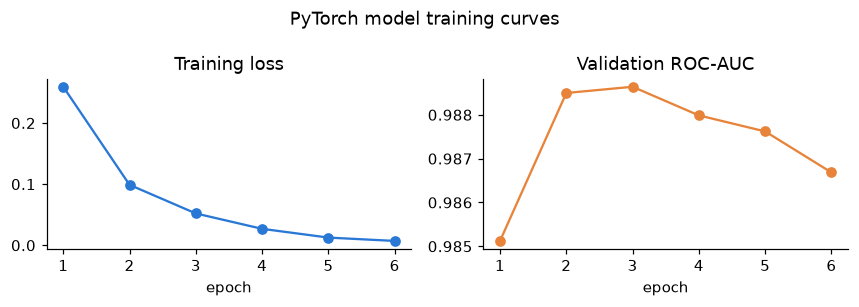

In [13]:
h = pd.DataFrame(history, columns=['epoch', 'train_loss', 'val_auc'])
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
ax[0].plot(h.epoch, h.train_loss, marker='o', color='#2a78d6'); ax[0].set_title('Training loss'); ax[0].set_xlabel('epoch')
ax[1].plot(h.epoch, h.val_auc, marker='o', color='#e8833a'); ax[1].set_title('Validation ROC-AUC'); ax[1].set_xlabel('epoch')
plt.suptitle('PyTorch model training curves'); plt.tight_layout(); plt.savefig(FIG / 'fig4_training.png'); plt.show()

## 6. Model 3 — GPT-2 perplexity (zero-shot)
**Perplexity** measures how "surprised" a language model is by a text. Text written by an LLM is usually
*more predictable* for another LLM → lower perplexity. No training: we only pick a threshold on the validation set.
GPT-2 runs on CPU, so we use a balanced sample of the test set and the first 128 tokens of each text.

In [14]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()
gtok = AutoTokenizer.from_pretrained('openai-community/gpt2')
gpt2 = AutoModelForCausalLM.from_pretrained('openai-community/gpt2').eval()

def perplexity(text):
    enc = gtok(text, return_tensors='pt', truncation=True, max_length=128)
    with torch.no_grad():
        return float(torch.exp(gpt2(**enc, labels=enc['input_ids']).loss))

va_s = va.groupby('y').sample(n=150, random_state=SEED)
te_s = te.groupby('y').sample(n=400, random_state=SEED)
t0 = time.time()
va_s = va_s.assign(ppl=va_s.text_clean.map(perplexity))
te_s = te_s.assign(ppl=te_s.text_clean.map(perplexity))
print(f'Perplexity computed for {len(va_s) + len(te_s)} texts in {time.time() - t0:.0f}s')
print(te_s.groupby('label').ppl.median().round(1).to_string())

Perplexity computed for 1100 texts in 237s
label
chatgpt    10.4
human      39.3


GPT-2 perplexity (zero-shot)           acc=0.954  F1=0.953  AUC=0.991  TPR@1%FPR=0.787


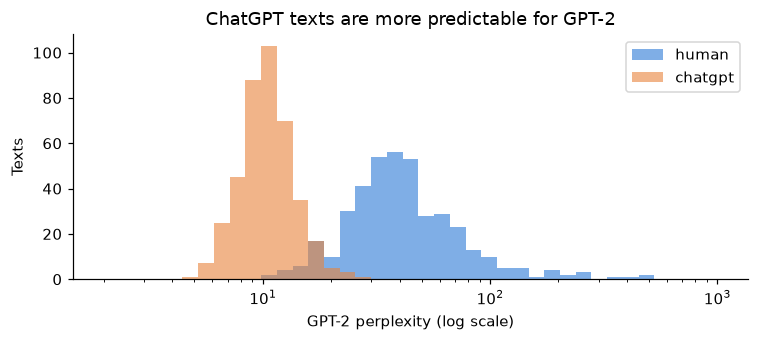

In [15]:
score = lambda d: -np.log(d.ppl.values)           # lower perplexity -> more likely ChatGPT
cands = np.quantile(score(va_s), np.linspace(0.05, 0.95, 91))
thr = max(cands, key=lambda t: accuracy_score(va_s.y, (score(va_s) >= t).astype(int)))
evaluate('GPT-2 perplexity (zero-shot)', te_s.y, score(te_s), thr=thr)

fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.logspace(0.3, 3, 40)
for lab, c in [('human', '#2a78d6'), ('chatgpt', '#e8833a')]:
    ax.hist(te_s.loc[te_s.label == lab, 'ppl'], bins=bins, alpha=0.6, label=lab, color=c)
ax.set_xscale('log'); ax.set_xlabel('GPT-2 perplexity (log scale)'); ax.set_ylabel('Texts'); ax.legend()
ax.set_title('ChatGPT texts are more predictable for GPT-2')
plt.tight_layout(); plt.savefig(FIG / 'fig5_perplexity.png'); plt.show()

## 7. Cross-domain generalisation (leave-one-domain-out)
A detector is useful only if it works on **topics it has never seen**.
We train TF-IDF + LogReg on 4 domains and test on the 5th, and compare with the in-domain score.

In [16]:
rows = []
for d in sorted(pairs.domain.unique()):
    in_te = te[te.domain == d]
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100_000, sublinear_tf=True,
                          token_pattern=r"(?u)\b\w+\b|[^\w\s]")
    out_tr = tr[tr.domain != d]
    lr = LogisticRegression(C=4, max_iter=2000).fit(vec.fit_transform(out_tr.text_clean), out_tr.y)
    unseen = pairs[pairs.domain == d]
    f1_unseen = f1_score(unseen.y, lr.predict(vec.transform(unseen.text_clean)))
    f1_in = f1_score(in_te.y, lr_cl.predict(vec_cl.transform(in_te.text_clean)))
    rows.append({'domain': d, 'F1 seen in training': f1_in, 'F1 unseen domain': f1_unseen})
lodo = pd.DataFrame(rows).set_index('domain').round(3)
lodo['drop'] = (lodo['F1 seen in training'] - lodo['F1 unseen domain']).round(3)
lodo

,F1 seen in training,F1 unseen domain,drop
domain,,,
finance,0.994,0.977,0.017
medicine,1.000,0.993,0.007
open_qa,0.939,0.849,0.090
reddit_eli5,0.991,0.860,0.131
wiki_csai,0.955,0.875,0.080


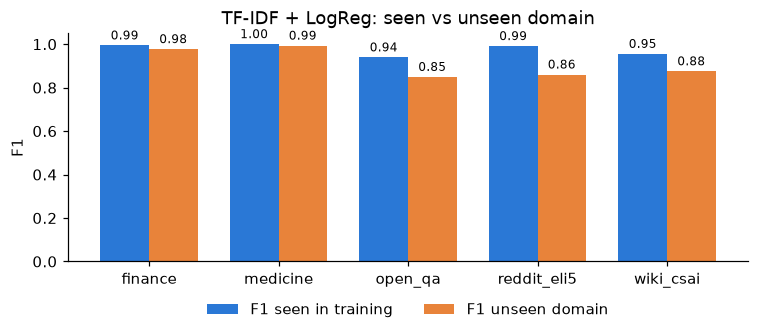

In [17]:
ax = lodo[['F1 seen in training', 'F1 unseen domain']].plot.bar(color=['#2a78d6', '#e8833a'], figsize=(7, 3.2), rot=0, width=0.75)
ax.set_ylim(0, 1.05); ax.set_ylabel('F1'); ax.set_xlabel('')
ax.set_title('TF-IDF + LogReg: seen vs unseen domain')
for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig(FIG / 'fig6_cross_domain.png'); plt.show()

## 8. Results summary

In [18]:
res = pd.DataFrame(RESULTS).T.round(3)
res

,accuracy,f1,roc_auc,tpr_at_1fpr
Length only (LogReg),0.752,0.771,0.766,0.000
TF-IDF + LogReg — RAW text,0.988,0.988,0.999,0.987
TF-IDF + LogReg — CLEANED text,0.987,0.987,0.999,0.984
PyTorch bag-of-embeddings — CLEANED,0.953,0.953,0.990,0.792
GPT-2 perplexity (zero-shot),0.954,0.953,0.991,0.788


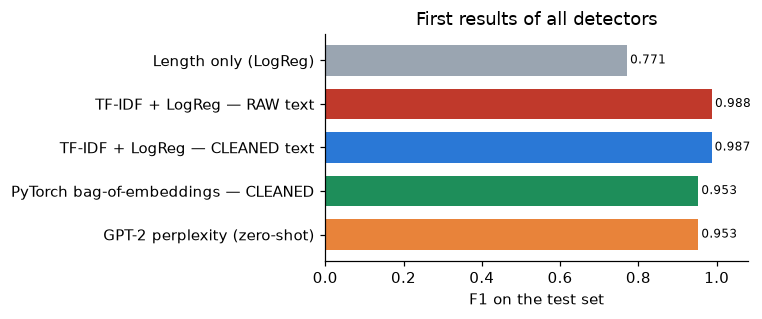

saved reports/results_midterm.json


In [19]:
ax = res['f1'].plot.barh(color=['#9aa5b1', '#c0392b', '#2a78d6', '#1e8e5a', '#e8833a'][:len(res)], figsize=(7, 3), width=0.7)
ax.set_xlim(0, 1.08); ax.set_xlabel('F1 on the test set'); ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt='%.3f', fontsize=8, padding=2)
ax.set_title('First results of all detectors'); plt.tight_layout(); plt.savefig(FIG / 'fig7_results.png'); plt.show()
out = {'results': RESULTS, 'cross_domain': lodo.reset_index().to_dict('records'),
       'n_pairs': int(len(pairs) // 2), 'split_sizes': pairs.split.value_counts().to_dict(),
       'ppl_median': te_s.groupby('label').ppl.median().round(1).to_dict(), 'pytorch_history': history,
       'cleaning_protocol': [(s, int(n)) for s, n in steps],
       'rule_accuracy': {'raw': float((rule(df.text) == df.label).mean()), 'cleaned': float((rule(df.text_clean) == df.label).mean())},
       'vocab_size': len(vocab), 'ppl_threshold': float(np.exp(-thr))}
Path('../reports/results_midterm.json').write_text(json.dumps(out, indent=2))
print('saved reports/results_midterm.json')